# Proyecto final: Predicción de ventas de videojuegos

**Dataset:** Video Game Sales (Kaggle)
**Objetivo:** Predecir las ventas globales de un videojuego según plataforma, año y género.

---

## 1. Selección del dataset

**Origen:** Dataset público de Kaggle  *Video Game Sales*

Se eligió este dataset para predecir las ventas globales de un videojuego en función de sus características iniciales (plataforma, año de lanzamiento y género). Es de tamaño moderado, formato tabular y permite aplicar de forma clara todas las etapas requeridas: limpieza, EDA y transformación.

## 2. Análisis exploratorio (EDA)

In [1]:
# Carga de datos
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset
df = pd.read_csv("https://raw.githubusercontent.com/jeqm0302/prediccion-ventas-videojuegos-ml/main/data/vgsales.csv")
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [2]:
# Analisis exploratorio inicial (EDA)
print("--- Información General ---")
df.info() # Vemos que datos tenemos y que nulos iniciales hay
print(" ")
# Detección de valores nulos
print("--- Valores nulos por columna ---")
print(df.isnull().sum())
print(f"\nTotal de valores nulos: {df.isnull().sum().sum()}")

--- Información General ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB
 
--- Valores nulos por columna ---
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global

# Estadística descriptiva

In [3]:
display(df.describe())

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


# Visualizacion de datos

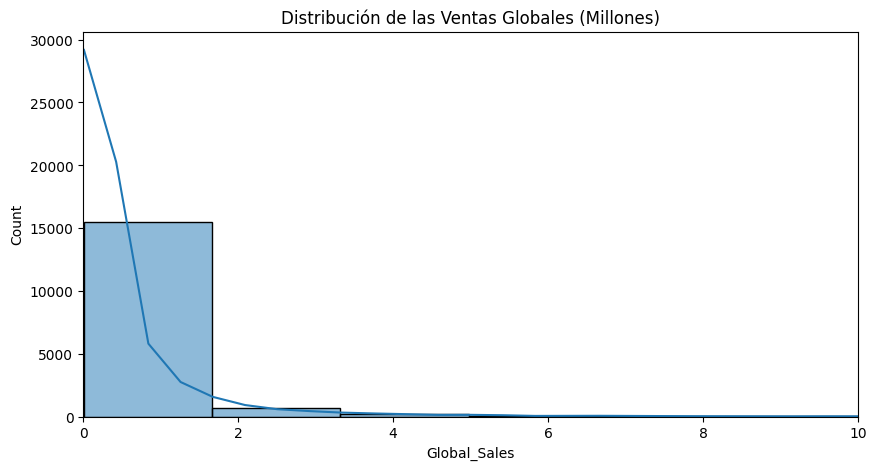

In [4]:
# Distribución de las ventas globales (frecuencia)
plt.figure(figsize=(10, 5))
sns.histplot(df['Global_Sales'], bins=50, kde=True)
plt.title('Distribución de las Ventas Globales (Millones)')
plt.xlim(0, 10) # Lo limitamos a 10 millones para visualizar mejor el grueso de los datos
plt.show()

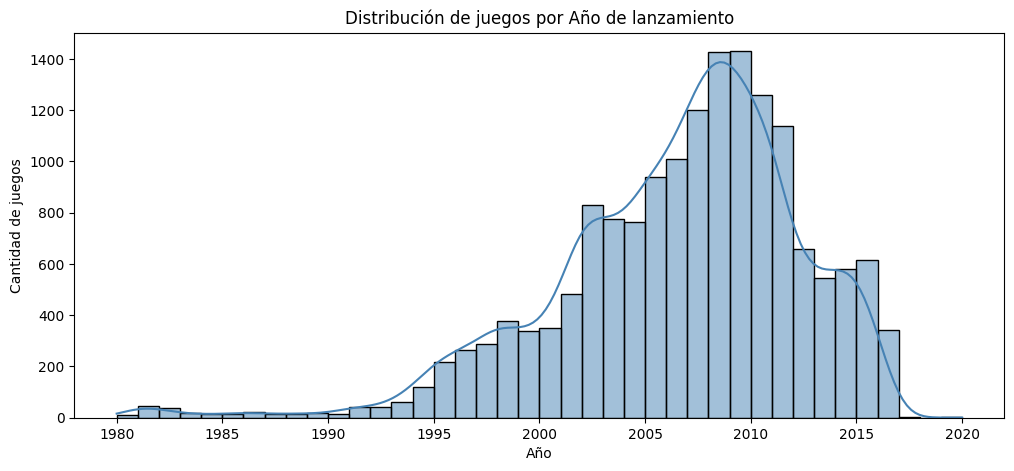

Año mínimo: 1980.0
Año máximo: 2020.0
Año más frecuente: 2009.0


In [5]:
# Distribución de la variable Year
plt.figure(figsize=(12, 5))
sns.histplot(df['Year'].dropna(), bins=40, kde=True, color='steelblue')
plt.title('Distribución de juegos por Año de lanzamiento')
plt.xlabel('Año')
plt.ylabel('Cantidad de juegos')
plt.show()

print(f"Año mínimo: {df['Year'].min()}")
print(f"Año máximo: {df['Year'].max()}")
print(f"Año más frecuente: {df['Year'].mode()[0]}")

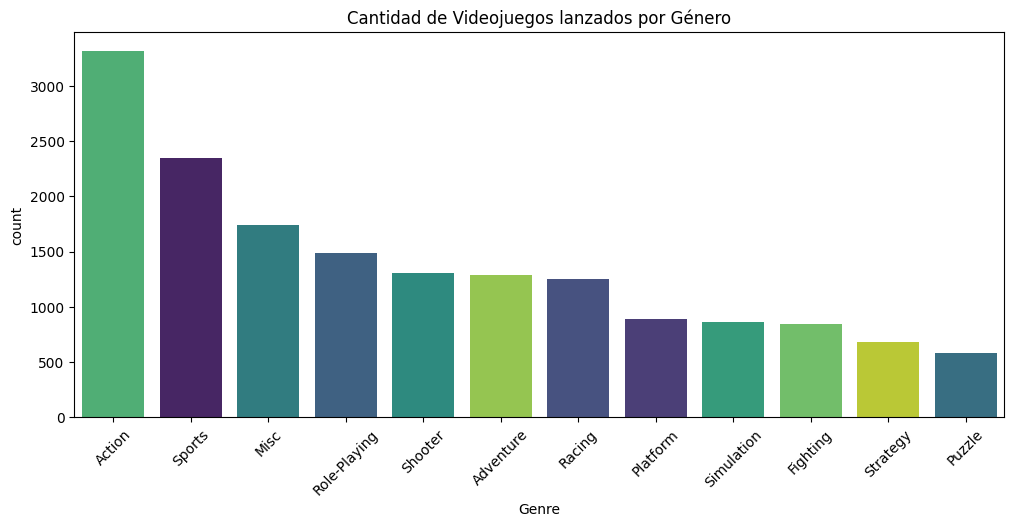

In [6]:
# Cantidad de juegos por género
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='Genre', order=df['Genre'].value_counts().index, hue='Genre', palette='viridis', legend=False)
plt.title('Cantidad de Videojuegos lanzados por Género')
plt.xticks(rotation=45)
plt.show()

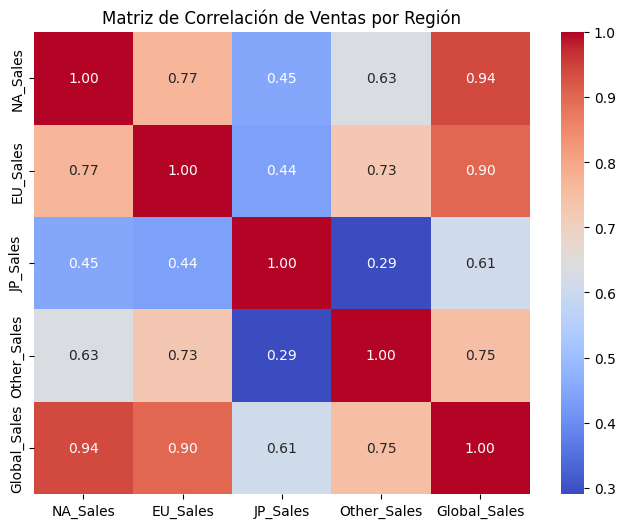

In [7]:
plt.figure(figsize=(8, 6))
columnas_numericas = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
sns.heatmap(df[columnas_numericas].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación de Ventas por Región')
plt.show()

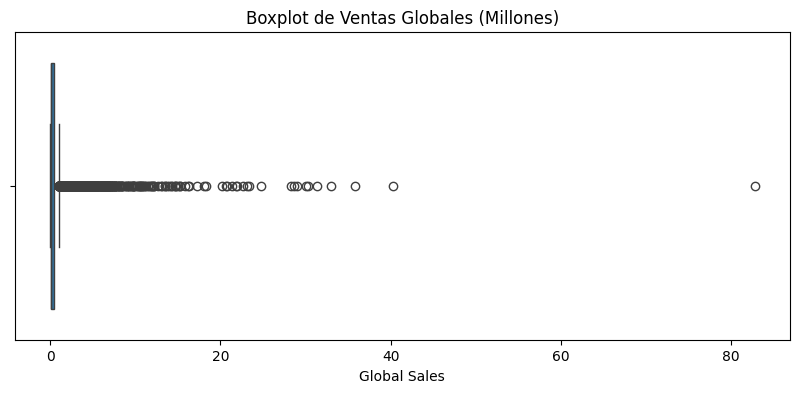

Q1: 0.06 | Q3: 0.47 | IQR: 0.41
Límite superior (Q3 + 1.5*IQR): 1.08
Cantidad de outliers detectados: 1893

Top 5 outliers:
                       Name Platform    Year  Global_Sales
0                Wii Sports      Wii  2006.0         82.74
1         Super Mario Bros.      NES  1985.0         40.24
2            Mario Kart Wii      Wii  2008.0         35.82
3         Wii Sports Resort      Wii  2009.0         33.00
4  Pokemon Red/Pokemon Blue       GB  1996.0         31.37


In [8]:
# Detección de outliers en Global_Sales
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['Global_Sales'])
plt.title('Boxplot de Ventas Globales (Millones)')
plt.xlabel('Global Sales')
plt.show()

# Cálculo de límites
Q1 = df['Global_Sales'].quantile(0.25)
Q3 = df['Global_Sales'].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR
outliers = df[df['Global_Sales'] > limite_superior]

print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
print(f"Límite superior (Q3 + 1.5*IQR): {limite_superior:.2f}")
print(f"Cantidad de outliers detectados: {len(outliers)}")
print(f"\nTop 5 outliers:")
print(outliers[['Name', 'Platform', 'Year', 'Global_Sales']].head())

**Observación**

Se detectaron valores extremos en Global_Sales,como por ejemplos: Wii Sports con 82.74M.
Donde los registros corresponden a lanzamientos reales y exitosos y no a errores de carga.

Por esta razón, se decide *conservarlos* en el dataset, para que el modelo pueda aprender que existen ventas excepcionales asociadas a ciertas características (plataforma, género).

## EDA profundo: análisis de plataformas, géneros y publishers

A continuación se profundiza el análisis exploratorio para identificar qué categorías concentran mayores ventas. Los hallazgos de esta sección justifican las decisiones de feature engineering que se aplicarán más adelante: creación de la variable `Década` para capturar el efecto temporal del mercado, `Generación_Consola` para agrupar plataformas por ciclo tecnológico, y agrupamiento de `Publisher` en top 20 + "Otros" para controlar la cardinalidad sin perder señal predictiva.


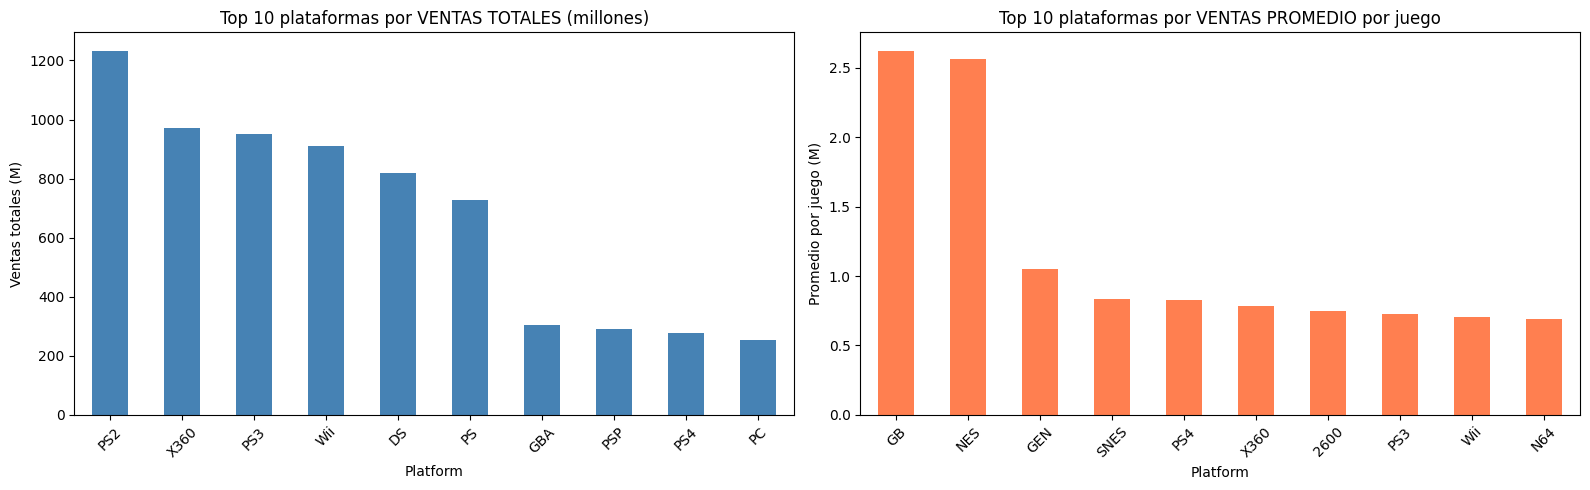

Observación: PS2 lidera en ventas totales (catálogo masivo), pero GB y NES
dominan en promedio por juego (catálogos chicos con hits legendarios).


In [9]:
# ============================================================
# EDA PROFUNDO: PLATAFORMAS, GÉNEROS Y PUBLISHERS
# ============================================================

# Trabajamos sobre df sin nulos en Year/Publisher para el análisis
df_eda = df.dropna(subset=['Year', 'Publisher']).copy()

# --- 1. Análisis por PLATAFORMA ---
plat_stats = df_eda.groupby('Platform').agg(
    n_juegos=('Global_Sales', 'count'),
    ventas_totales=('Global_Sales', 'sum'),
    ventas_promedio=('Global_Sales', 'mean')
).round(3)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

plat_stats.sort_values('ventas_totales', ascending=False).head(10)['ventas_totales'].plot(
    kind='bar', ax=axes[0], color='steelblue'
)
axes[0].set_title('Top 10 plataformas por VENTAS TOTALES (millones)')
axes[0].set_ylabel('Ventas totales (M)')
axes[0].tick_params(axis='x', rotation=45)

plat_stats.sort_values('ventas_promedio', ascending=False).head(10)['ventas_promedio'].plot(
    kind='bar', ax=axes[1], color='coral'
)
axes[1].set_title('Top 10 plataformas por VENTAS PROMEDIO por juego')
axes[1].set_ylabel('Promedio por juego (M)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("Observación: PS2 lidera en ventas totales (catálogo masivo), pero GB y NES")
print("dominan en promedio por juego (catálogos chicos con hits legendarios).")

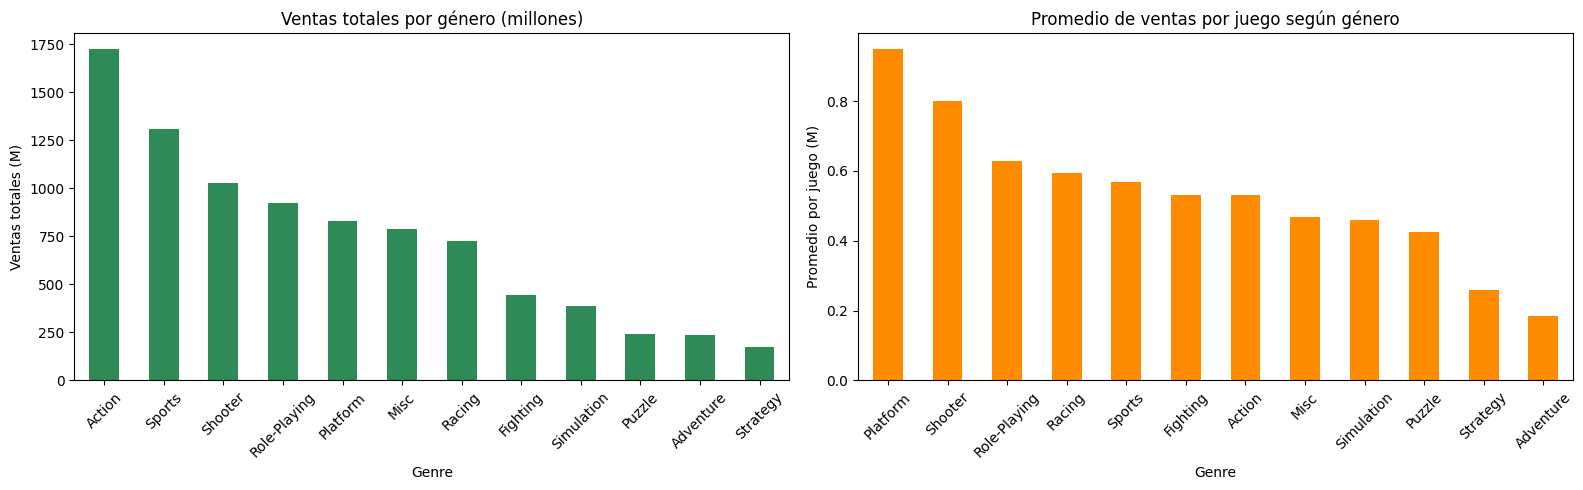

Observación: Action lidera en volumen (3251 juegos), pero Platform y Shooter
son los géneros con mayor rendimiento promedio por título.


In [10]:
# --- 2. Análisis por GÉNERO ---
genre_stats = df_eda.groupby('Genre').agg(
    n_juegos=('Global_Sales', 'count'),
    ventas_totales=('Global_Sales', 'sum'),
    ventas_promedio=('Global_Sales', 'mean')
).round(3).sort_values('ventas_totales', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

genre_stats['ventas_totales'].plot(kind='bar', ax=axes[0], color='seagreen')
axes[0].set_title('Ventas totales por género (millones)')
axes[0].set_ylabel('Ventas totales (M)')
axes[0].tick_params(axis='x', rotation=45)

genre_stats.sort_values('ventas_promedio', ascending=False)['ventas_promedio'].plot(
    kind='bar', ax=axes[1], color='darkorange'
)
axes[1].set_title('Promedio de ventas por juego según género')
axes[1].set_ylabel('Promedio por juego (M)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("Observación: Action lidera en volumen (3251 juegos), pero Platform y Shooter")
print("son los géneros con mayor rendimiento promedio por título.")

Total de publishers únicos: 576
Top 10 publishers concentran: 70.6% de las ventas
Top 20 publishers concentran: 85.7% de las ventas


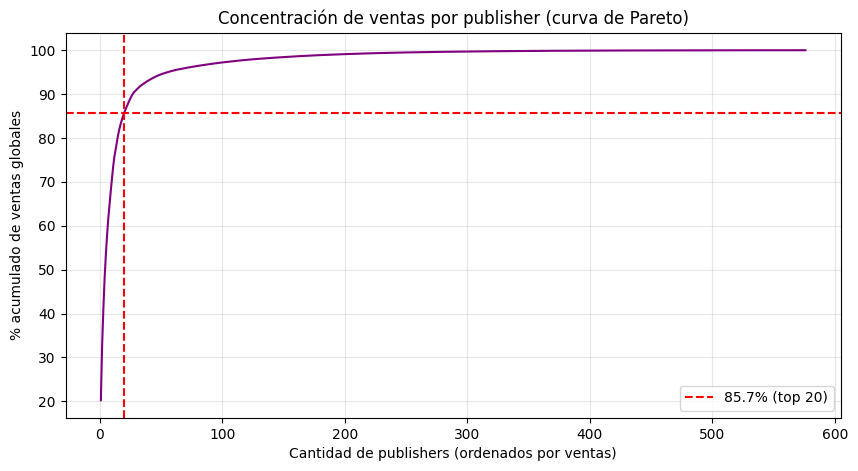


Justificación: agrupar los 556 publishers menores como 'Otros' controla
la cardinalidad sin perder señal predictiva relevante.


In [11]:
# --- 3. Análisis por PUBLISHER: cardinalidad y concentración ---
pub_stats = df_eda.groupby('Publisher')['Global_Sales'].sum().sort_values(ascending=False)

print(f"Total de publishers únicos: {df_eda['Publisher'].nunique()}")
print(f"Top 10 publishers concentran: {(pub_stats.head(10).sum()/pub_stats.sum())*100:.1f}% de las ventas")
print(f"Top 20 publishers concentran: {(pub_stats.head(20).sum()/pub_stats.sum())*100:.1f}% de las ventas")

# Gráfico: acumulado de ventas por cantidad de publishers ordenados
cumsum_pct = (pub_stats.cumsum() / pub_stats.sum()) * 100
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cumsum_pct)+1), cumsum_pct.values, color='purple')
plt.axhline(y=85.7, color='red', linestyle='--', label='85.7% (top 20)')
plt.axvline(x=20, color='red', linestyle='--')
plt.xlabel('Cantidad de publishers (ordenados por ventas)')
plt.ylabel('% acumulado de ventas globales')
plt.title('Concentración de ventas por publisher (curva de Pareto)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nJustificación: agrupar los 556 publishers menores como 'Otros' controla")
print("la cardinalidad sin perder señal predictiva relevante.")

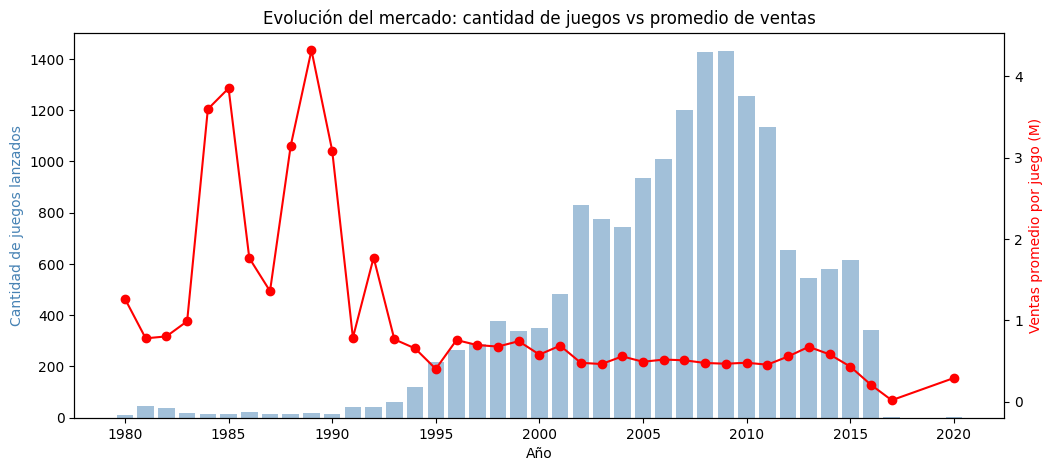

Observación: a medida que aumenta el volumen de lanzamientos, cae el promedio
de ventas por juego. Esto justifica crear la variable 'Década' para capturar
el efecto temporal del mercado.


In [12]:
# --- 4. Análisis temporal: evolución de ventas ---
year_stats = df_eda.groupby('Year').agg(
    n_juegos=('Global_Sales', 'count'),
    ventas_promedio=('Global_Sales', 'mean')
).round(3)

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

ax1.bar(year_stats.index, year_stats['n_juegos'], alpha=0.5, color='steelblue', label='N° de juegos')
ax2.plot(year_stats.index, year_stats['ventas_promedio'], color='red', marker='o', label='Promedio ventas')

ax1.set_xlabel('Año')
ax1.set_ylabel('Cantidad de juegos lanzados', color='steelblue')
ax2.set_ylabel('Ventas promedio por juego (M)', color='red')
plt.title('Evolución del mercado: cantidad de juegos vs promedio de ventas')
plt.show()

print("Observación: a medida que aumenta el volumen de lanzamientos, cae el promedio")
print("de ventas por juego. Esto justifica crear la variable 'Década' para capturar")
print("el efecto temporal del mercado.")

# Observaciones
*   *Valores nulos*: Se identificaron valores faltantes en las columnas Year (271 nulos) y Publisher (58 nulos) mediante los comandos df.info() y df.isnull().sum(). Al representar un porcentaje muy bajo del total de los datos (menos del 2%), se tomó la decisión técnica de eliminar esas filas incompletas para no introducir ruido al modelo.

*   *Selección de variables*: En esta pre-entrega se tomó la decisión de eliminar las columnas "Rank" y "Name" porque, en esta instancia, no aportan algún poder predictivo generalizable. Además, se determinó eliminar las ventas regionales para evitar la fuga de datos, ya que la suma de esos valores es lo que queremos predecir.

*   *Codificación y escalado*: En esta parte, transformamos las variables categóricas "Platform" y "Genre" a un formato numérico (One-Hot Encoding) para que el modelo entienda las categorías sin inventar algún orden jerárquico entre ellas. Además, en la variable numérica "Year" aplicaremos un proceso de escalado para comprimir su magnitud; esto evita que el año no aplane a las demás variables, permitiendo al modelo aprender de forma equilibrada de todos los datos.

## Feature Engineering

A partir de los hallazgos del EDA profundo, se crean tres variables derivadas que enriquecen el poder predictivo del modelo:

- **`Decada`**: extraída de `Year` para capturar el efecto temporal del mercado. El EDA mostró que los promedios de ventas por juego caen de 1.84M (años 80) a 0.49M (años 2010) a medida que se satura el mercado.

- **`Generacion_Consola`**: mapea las 31 plataformas a su ciclo generacional (Gen 2 a Gen 8, más una categoría 0 para PC). Complementa a `Platform` capturando patrones de ciclo tecnológico que la plataforma sola no expresa.

- **`Publisher_Agrupado`**: dado que existen 576 publishers únicos y los top 20 concentran el 85.7% de las ventas, se conservan los top 20 como categorías propias y el resto se agrupa como "Otros". Esto incorpora la señal predictiva del publisher (Nintendo con promedio 2.56M/juego) sin explotar la cardinalidad.

In [13]:
# ============================================================
# FEATURE ENGINEERING: creación de variables derivadas
# ============================================================
# Se trabaja sobre df_limpio (sin nulos en Year/Publisher).

# Partimos del df original y limpiamos nulos
df_fe = df.dropna(subset=['Year', 'Publisher']).copy()
df_fe = df_fe.drop_duplicates()

# --- 1. Variable DECADA ---
# Ejemplo: 2006 → 2000, 1985 → 1980
df_fe['Decada'] = (df_fe['Year'] // 10 * 10).astype(int)

# --- 2. Variable GENERACION_CONSOLA ---
# Mapeo basado en generaciones estándar de la industria.
# PC recibe categoría 0 porque no encaja en el ciclo generacional de consolas.
generacion_map = {
    '2600': 2,
    'NES': 3,
    'GB': 4, 'SNES': 4, 'GEN': 4, 'SCD': 4, 'NG': 4, 'TG16': 4, 'GG': 4,
    'PS': 5, 'N64': 5, 'SAT': 5, '3DO': 5, 'PCFX': 5,
    'GBA': 6, 'PS2': 6, 'XB': 6, 'GC': 6, 'DC': 6, 'WS': 6,
    'DS': 7, 'PS3': 7, 'X360': 7, 'Wii': 7, 'PSP': 7,
    '3DS': 8, 'PS4': 8, 'XOne': 8, 'WiiU': 8, 'PSV': 8,
    'PC': 0
}
df_fe['Generacion_Consola'] = df_fe['Platform'].map(generacion_map)

# Verificación: ninguna plataforma sin mapear
sin_mapear = df_fe['Generacion_Consola'].isna().sum()
print(f"Plataformas sin mapear en Generacion_Consola: {sin_mapear}")

# --- 3. Variable PUBLISHER_AGRUPADO ---
# Identificamos los top 20 publishers por ventas totales.
top_20_publishers = (
    df_fe.groupby('Publisher')['Global_Sales']
    .sum()
    .sort_values(ascending=False)
    .head(20)
    .index
    .tolist()
)

# Los que no están en el top 20 pasan a la categoría 'Otros'.
df_fe['Publisher_Agrupado'] = df_fe['Publisher'].apply(
    lambda x: x if x in top_20_publishers else 'Otros'
)

print(f"\nCantidad de categorías en Publisher_Agrupado: {df_fe['Publisher_Agrupado'].nunique()}")
print(f"(20 publishers top + 'Otros' = 21 categorías)")

# --- Verificación general de las nuevas variables ---
print("\nVista previa de las nuevas variables:")
print(df_fe[['Year', 'Decada', 'Platform', 'Generacion_Consola', 'Publisher', 'Publisher_Agrupado']].head())

Plataformas sin mapear en Generacion_Consola: 0

Cantidad de categorías en Publisher_Agrupado: 21
(20 publishers top + 'Otros' = 21 categorías)

Vista previa de las nuevas variables:
     Year  Decada Platform  Generacion_Consola Publisher Publisher_Agrupado
0  2006.0    2000      Wii                   7  Nintendo           Nintendo
1  1985.0    1980      NES                   3  Nintendo           Nintendo
2  2008.0    2000      Wii                   7  Nintendo           Nintendo
3  2009.0    2000      Wii                   7  Nintendo           Nintendo
4  1996.0    1990       GB                   4  Nintendo           Nintendo


## Verificación de la distribución del split

Dado que `Global_Sales` presenta una distribución muy sesgada con outliers extremos (Wii Sports = 82.74M), un split puramente aleatorio puede repartir mal los valores extremos entre train y test. En este caso verificamos la distribución de la variable objetivo en ambos conjuntos y, si es necesario, se aplica un split estratificado para asegurar una representación equilibrada.

Datos listos para modelar:
Tamaño X_train: (13032, 64)
Tamaño X_test:  (3259, 64)
Nulos restantes en X_train: 0

Distribución de Global_Sales en cada conjunto:
         y_train    y_test
count  13032.000  3259.000
mean       0.542     0.537
std        1.572     1.548
min        0.010     0.010
25%        0.060     0.060
50%        0.170     0.170
75%        0.480     0.480
max       82.740    35.820


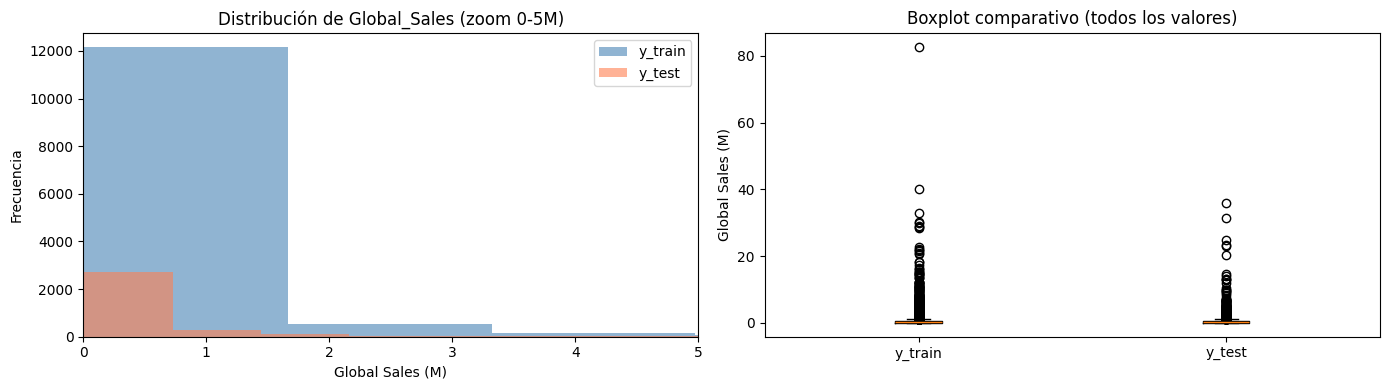


Máximo en y_train: 82.74
Máximo en y_test:  35.82
Con estratificación, ambos conjuntos incluyen valores extremos representativos.


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# ============================================================
# PIPELINE FINAL: selección, codificación, división y escalado
# ============================================================

# 1. Selección de variables relevantes
columnas_a_eliminar = ['Rank', 'Name', 'Publisher',
                       'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']
df_reducido = df_fe.drop(columns=columnas_a_eliminar)

# 2. Codificación de variables categóricas con One-Hot Encoding
df_transformado = pd.get_dummies(
    df_reducido,
    columns=['Platform', 'Genre', 'Publisher_Agrupado'],
    drop_first=True
)

# 3. Separación X / y
X = df_transformado.drop(columns=['Global_Sales'])
y = df_transformado['Global_Sales']

# 4. División train/test ESTRATIFICADA por cuantiles de Global_Sales
# Creamos bins de la variable objetivo para estratificar
# Esto asegura que los valores bajos, medios, altos y extremos
# queden distribuidos proporcionalmente en train y test.
bins_y = pd.cut(y,
                bins=[-0.01, 0.06, 0.17, 0.47, 5, y.max()],
                labels=['muy_bajo', 'bajo', 'medio', 'alto', 'extremo'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=bins_y
)

# 5. Escalado de variables numéricas (Year y Decada)
scaler = StandardScaler()
columnas_a_escalar = ['Year', 'Decada']
X_train[columnas_a_escalar] = scaler.fit_transform(X_train[columnas_a_escalar])
X_test[columnas_a_escalar] = scaler.transform(X_test[columnas_a_escalar])

# --- Verificación del split ---
print("Datos listos para modelar:")
print(f"Tamaño X_train: {X_train.shape}")
print(f"Tamaño X_test:  {X_test.shape}")
print(f"Nulos restantes en X_train: {X_train.isnull().sum().sum()}")

# Comparación estadística de la variable objetivo
print("\nDistribución de Global_Sales en cada conjunto:")
comparacion = pd.DataFrame({
    'y_train': y_train.describe(),
    'y_test': y_test.describe()
}).round(3)
print(comparacion)

# Visualización comparativa: histogramas superpuestos
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(y_train, bins=50, alpha=0.6, label='y_train', color='steelblue')
axes[0].hist(y_test, bins=50, alpha=0.6, label='y_test', color='coral')
axes[0].set_xlim(0, 5)
axes[0].set_title('Distribución de Global_Sales (zoom 0-5M)')
axes[0].set_xlabel('Global Sales (M)')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()

# Boxplots para ver los extremos
axes[1].boxplot([y_train, y_test], tick_labels=['y_train', 'y_test'])
axes[1].set_title('Boxplot comparativo (todos los valores)')
axes[1].set_ylabel('Global Sales (M)')

plt.tight_layout()
plt.show()

print(f"\nMáximo en y_train: {y_train.max()}")
print(f"Máximo en y_test:  {y_test.max()}")
print("Con estratificación, ambos conjuntos incluyen valores extremos representativos.")

---

# 3. Entrega Final: Modelado y evaluación

## 3.1. Elección del modelo

### Tipo de problema

El objetivo es predecir `Global_Sales`, una variable **numérica continua** (millones de unidades vendidas), por lo que corresponde a un problema de **regresión supervisada**. Descartamos técnicas de clasificación porque el target no representa categorías discretas.

### Modelos seleccionados

Se entrenarán y compararán **dos modelos** con perfiles complementarios:

**1. Regresión Lineal con regularización Ridge (baseline)**

- Modelo interpretable: los coeficientes indican de forma directa cómo cada variable influye en la predicción.
- Sirve como *punto de comparación* para evaluar si un modelo más complejo realmente aporta ganancia.
- La variante Ridge (regularización L2) es preferible a la regresión lineal simple porque nuestro dataset tiene **64 variables**, muchas de ellas dummies correlacionadas entre sí (por ejemplo, distintas versiones de PlayStation). Ridge controla la varianza de los coeficientes y evita sobreajuste.

**2. Random Forest Regressor (modelo principal)**

- Ensamble de árboles de decisión, capaz de capturar **relaciones no lineales** e **interacciones** entre variables (por ejemplo, la interacción Plataforma × Género × Década, que un modelo lineal no puede modelar).
- Robusto frente a outliers (Wii Sports, Super Mario Bros.) porque cada árbol trabaja con submuestras.
- Permite obtener **importancia de features**, útil para interpretar qué variables aportan más al predecir ventas.
- No requiere que las variables estén escaladas ni que la variable objetivo sea simétrica.

### Estrategia de transformación del target

`Global_Sales` presenta una distribución muy sesgada a la derecha: la mediana es 0.17M pero el máximo llega a 82.74M. Esta asimetría dificulta el aprendizaje, especialmente para modelos lineales.

Por eso, para el entrenamiento aplicaremos una **transformación logarítmica** (`log1p`) sobre el target. Esta transformación comprime la cola larga y produce una distribución más simétrica. Al momento de reportar métricas y visualizaciones, las predicciones se devuelven a la escala original con `expm1` para que los valores sean interpretables en millones de unidades.

### Criterio de comparación

Ambos modelos serán evaluados con las siguientes métricas de regresión:

- **MAE** (Error Absoluto Medio): promedio del error absoluto en millones de unidades. Interpretación directa.
- **RMSE** (Raíz del Error Cuadrático Medio): penaliza más los errores grandes. Útil dado que existen outliers.
- **R²** (Coeficiente de determinación): proporción de la varianza explicada por el modelo (entre 0 y 1).

Se aplicará además **validación cruzada K-Fold (k=5)** sobre el conjunto de entrenamiento para estimar el rendimiento de forma más robusta, evitando depender de un único split.

## 3.2. Entrenamiento del modelo baseline: Regresión Ridge

Se entrena una **Regresión Ridge** como modelo base. La regularización L2 (parámetro `alpha`) controla la magnitud de los coeficientes, previniendo el sobreajuste que puede ocurrir por la alta cantidad de variables dummies correlacionadas (64 columnas).

Se aplica la transformación logarítmica `log1p` sobre el target durante el entrenamiento, y las predicciones se revierten con `expm1` para obtener valores interpretables en millones de unidades.

In [15]:
from sklearn.linear_model import Ridge
import numpy as np

# ============================================================
# ENTRENAMIENTO DEL MODELO BASELINE: Regresión Ridge
# ============================================================

# 1. Transformación logarítmica del target
# log1p(x) = log(1 + x), maneja bien valores cercanos a 0 y comprime la cola larga
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

print("Comparación de la distribución del target antes y después de log1p:")
print(f"  y_train original  -> min: {y_train.min():.2f} | mediana: {y_train.median():.2f} | max: {y_train.max():.2f}")
print(f"  y_train log1p     -> min: {y_train_log.min():.2f} | mediana: {y_train_log.median():.2f} | max: {y_train_log.max():.2f}")

# 2. Instanciamos y entrenamos el modelo Ridge
# alpha=1.0 es un valor por defecto razonable, se puede ajustar más adelante
modelo_ridge = Ridge(alpha=1.0, random_state=42)
modelo_ridge.fit(X_train, y_train_log)

print("\nModelo Ridge entrenado correctamente.")
print(f"Cantidad de coeficientes aprendidos: {len(modelo_ridge.coef_)}")

# 3. Predicciones sobre el conjunto de test
# Devolvemos las predicciones a la escala original con expm1 (inverso de log1p)
y_pred_ridge_log = modelo_ridge.predict(X_test)
y_pred_ridge = np.expm1(y_pred_ridge_log)

# Evitamos predicciones negativas (una venta no puede ser < 0)
y_pred_ridge = np.clip(y_pred_ridge, 0, None)

# 4. Vista previa de predicciones vs valores reales
resultados_ridge = pd.DataFrame({
    'Real (M)': y_test.values,
    'Predicho Ridge (M)': y_pred_ridge.round(3)
}).head(10)

print("\nPrimeras 10 predicciones vs valores reales:")
print(resultados_ridge)

# 5. Guardamos las predicciones para comparar después con Random Forest
print("\nRidge entrenado y predicciones guardadas en 'y_pred_ridge'.")

Comparación de la distribución del target antes y después de log1p:
  y_train original  -> min: 0.01 | mediana: 0.17 | max: 82.74
  y_train log1p     -> min: 0.01 | mediana: 0.16 | max: 4.43

Modelo Ridge entrenado correctamente.
Cantidad de coeficientes aprendidos: 64

Primeras 10 predicciones vs valores reales:
   Real (M)  Predicho Ridge (M)
0      0.19               0.050
1      0.07               1.215
2      0.23               0.297
3      0.01               0.092
4      0.30               0.175
5      0.16               0.196
6      2.23               0.381
7      0.30               0.317
8      0.22               0.279
9      0.06               0.405

Ridge entrenado y predicciones guardadas en 'y_pred_ridge'.


## 3.3. Entrenamiento del modelo avanzado: Random Forest Regressor

Se entrena un **Random Forest Regressor** como modelo principal. A diferencia de Ridge, este modelo es capaz de capturar **relaciones no lineales** e **interacciones entre variables** sin necesidad de que sean especificadas manualmente. Por ejemplo, puede aprender que un juego de género `Sports` en plataforma `Wii` durante los años 2000 tiene un comportamiento de ventas distinto que el mismo género en otras combinaciones.

Se utiliza la misma transformación logarítmica del target aplicada al modelo Ridge, para que la comparación entre ambos sea justa.

**Hiperparámetros elegidos:**
- `n_estimators=200`: cantidad de árboles del bosque. Un valor moderado que equilibra rendimiento y tiempo de entrenamiento.
- `max_depth=15`: profundidad máxima de cada árbol. Limitar la profundidad previene el sobreajuste (los árboles muy profundos memorizan los datos de entrenamiento).
- `min_samples_leaf=5`: mínimo de muestras por hoja. Evita hojas demasiado específicas que respondan al ruido.
- `random_state=42`: reproducibilidad de resultados.
- `n_jobs=-1`: utiliza todos los núcleos del procesador para acelerar el entrenamiento.

In [16]:
from sklearn.ensemble import RandomForestRegressor

# ============================================================
# ENTRENAMIENTO DEL MODELO AVANZADO: Random Forest Regressor
# ============================================================

# 1. Instanciamos el modelo con hiperparámetros seleccionados
modelo_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# 2. Entrenamos sobre el mismo target transformado con log1p
print("Entrenando Random Forest")
modelo_rf.fit(X_train, y_train_log)
print("Modelo Random Forest entrenado correctamente.")
print(f"Cantidad de árboles: {modelo_rf.n_estimators}")
print(f"Profundidad máxima permitida: {modelo_rf.max_depth}")

# 3. Predicciones sobre el conjunto de test
y_pred_rf_log = modelo_rf.predict(X_test)
y_pred_rf = np.expm1(y_pred_rf_log)

# Evitamos predicciones negativas
y_pred_rf = np.clip(y_pred_rf, 0, None)

# 4. Vista previa comparativa: Real vs Ridge vs Random Forest
resultados_comparacion = pd.DataFrame({
    'Real (M)': y_test.values,
    'Predicho Ridge (M)': y_pred_ridge.round(3),
    'Predicho RF (M)': y_pred_rf.round(3)
}).head(15)

print("\nPrimeras 15 predicciones comparativas:")
print(resultados_comparacion)

# 5. Análisis rápido de errores promedio (sin cálculo formal todavía)
error_ridge_promedio = np.abs(y_test.values - y_pred_ridge).mean()
error_rf_promedio = np.abs(y_test.values - y_pred_rf).mean()

print(f"\nError promedio absoluto (vista previa):")
print(f"  Ridge:         {error_ridge_promedio:.4f} millones")
print(f"  Random Forest: {error_rf_promedio:.4f} millones")
print("\nEn el próximo paso calcularemos las métricas formales (MAE, RMSE, R²).")

Entrenando Random Forest
Modelo Random Forest entrenado correctamente.
Cantidad de árboles: 200
Profundidad máxima permitida: 15

Primeras 15 predicciones comparativas:
    Real (M)  Predicho Ridge (M)  Predicho RF (M)
0       0.19               0.050            0.068
1       0.07               1.215            0.708
2       0.23               0.297            0.291
3       0.01               0.092            0.110
4       0.30               0.175            0.159
5       0.16               0.196            0.301
6       2.23               0.381            0.306
7       0.30               0.317            0.427
8       0.22               0.279            0.532
9       0.06               0.405            0.280
10      0.59               0.407            0.392
11      0.10               0.518            0.396
12      0.17               0.257            0.233
13      0.92               0.405            0.227
14      0.09               0.407            0.845

Error promedio absoluto (vista

## 3.4. Evaluación con métricas formales

Se calculan las métricas de regresión estándar sobre el conjunto de test para ambos modelos:

- **MAE (Mean Absolute Error)**: promedio del valor absoluto de los errores. Se interpreta directamente en millones de unidades vendidas.
- **RMSE (Root Mean Squared Error)**: raíz del error cuadrático medio. Penaliza más fuerte los errores grandes, por lo que es sensible a los outliers.
- **R² (Coeficiente de determinación)**: proporción de la varianza total del target que el modelo logra explicar. Valores cercanos a 1 indican mejor ajuste; un valor de 0 equivale a predecir siempre la media.

MÉTRICAS DE EVALUACIÓN SOBRE CONJUNTO DE TEST
           Ridge  Random Forest
MAE (M)   0.4436         0.4413
RMSE (M)  1.4636         1.4735
R²        0.1060         0.0937

INTERPRETACIÓN
Mejor MAE  (menor es mejor): Random Forest
Mejor RMSE (menor es mejor): Ridge
Mejor R²   (mayor es mejor): Ridge


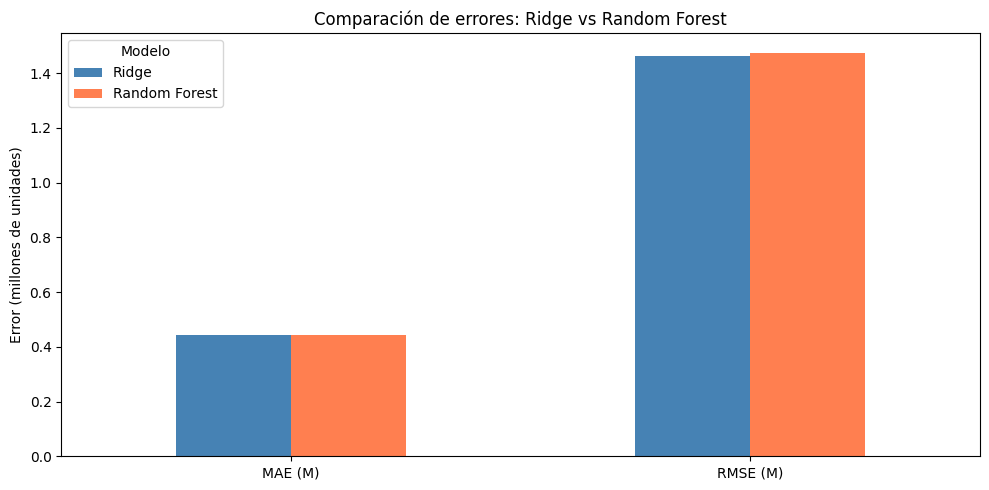


Escala del problema:
  Rango de Global_Sales en test: 0.01 - 35.82 millones
  Mediana de Global_Sales en test: 0.17 millones
  Un MAE de ~0.44M significa que en promedio el modelo se equivoca por esa cantidad.


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ============================================================
# EVALUACIÓN CON MÉTRICAS FORMALES
# ============================================================

# 1. Cálculo de métricas para Ridge
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

# 2. Cálculo de métricas para Random Forest
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

# 3. Tabla comparativa
metricas = pd.DataFrame({
    'Ridge': [mae_ridge, rmse_ridge, r2_ridge],
    'Random Forest': [mae_rf, rmse_rf, r2_rf]
}, index=['MAE (M)', 'RMSE (M)', 'R²']).round(4)

print("="*55)
print("MÉTRICAS DE EVALUACIÓN SOBRE CONJUNTO DE TEST")
print("="*55)
print(metricas)

# 4. Interpretación automática del mejor modelo por métrica
print("\n" + "="*55)
print("INTERPRETACIÓN")
print("="*55)

mejor_mae = 'Ridge' if mae_ridge < mae_rf else 'Random Forest'
mejor_rmse = 'Ridge' if rmse_ridge < rmse_rf else 'Random Forest'
mejor_r2 = 'Ridge' if r2_ridge > r2_rf else 'Random Forest'

print(f"Mejor MAE  (menor es mejor): {mejor_mae}")
print(f"Mejor RMSE (menor es mejor): {mejor_rmse}")
print(f"Mejor R²   (mayor es mejor): {mejor_r2}")

# 5. Visualización comparativa
fig, ax = plt.subplots(figsize=(10, 5))
metricas_plot = metricas.loc[['MAE (M)', 'RMSE (M)']]
metricas_plot.plot(kind='bar', ax=ax, color=['steelblue', 'coral'])
ax.set_title('Comparación de errores: Ridge vs Random Forest')
ax.set_ylabel('Error (millones de unidades)')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Modelo')
plt.tight_layout()
plt.show()

# 6. Observación numérica adicional
print(f"\nEscala del problema:")
print(f"  Rango de Global_Sales en test: {y_test.min():.2f} - {y_test.max():.2f} millones")
print(f"  Mediana de Global_Sales en test: {y_test.median():.2f} millones")
print(f"  Un MAE de ~{mae_rf:.2f}M significa que en promedio el modelo se equivoca por esa cantidad.")

## 3.5. Validación cruzada (K-Fold)

La evaluación anterior utilizó un único split de train/test, lo que puede reflejar particularidades del conjunto de test elegido. Para estimar el rendimiento de forma más robusta, se aplica **validación cruzada con K-Fold (k=5)** sobre el conjunto de entrenamiento.

En este esquema, el conjunto de entrenamiento se divide en 5 partes iguales. El modelo se entrena 5 veces, y en cada iteración usa 4 partes para entrenar y 1 para validar. Al final se obtienen 5 valores de cada métrica que se promedian, junto con su desvío estándar.

Un desvío bajo indica que el modelo tiene **rendimiento estable** independientemente de la partición usada. Un desvío alto indica sensibilidad al conjunto de datos.

Ejecutando validación cruzada (puede tardar unos minutos)...

Ridge - Validación cruzada completada.
Random Forest - Validación cruzada completada.

RESULTADOS DE VALIDACIÓN CRUZADA (5 folds)
Nota: MAE y RMSE están en escala logarítmica (log1p),
      no directamente comparables con las métricas del paso anterior.
      El R² de CV (escala log) tampoco es comparable con el R² de test (escala original).

                      Ridge    Random Forest
MAE (log)   0.2243 ± 0.0044  0.2145 ± 0.0027
RMSE (log)  0.3432 ± 0.0101  0.3369 ± 0.0071
R²          0.2572 ± 0.0185  0.2840 ± 0.0260


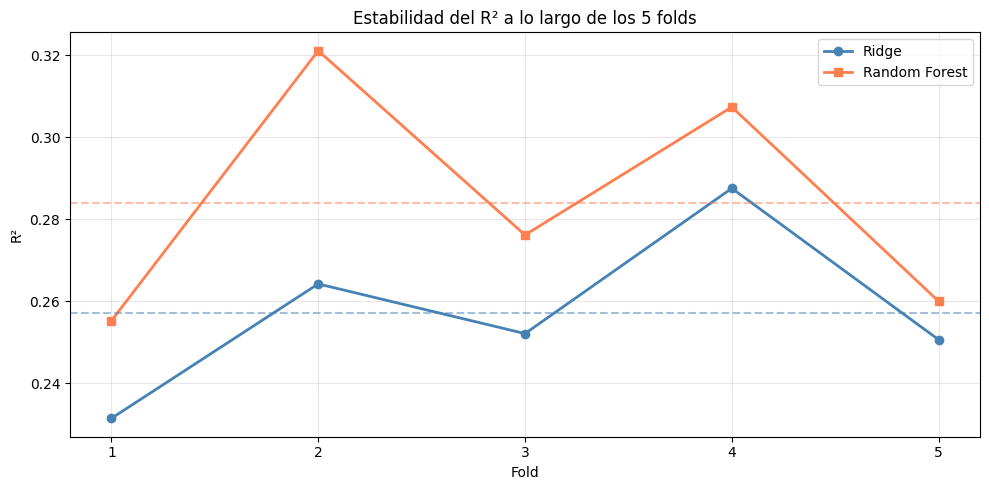


INTERPRETACIÓN
Mejor R² promedio en CV: Random Forest

Ridge         -> R² medio: 0.2572 | Desvío: 0.0185
Random Forest -> R² medio: 0.2840 | Desvío: 0.0260

Ridge muestra menor desvío -> rendimiento más estable entre folds.


In [18]:
from sklearn.model_selection import cross_val_score, KFold

# ============================================================
# VALIDACIÓN CRUZADA CON K-FOLD (k=5)
# ============================================================

# 1. Definimos el esquema de validación cruzada
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Recordar: entrenamos con y_train_log (target transformado)
# scikit-learn calcula las métricas en la escala en que se entrenó

print("Ejecutando validación cruzada (puede tardar unos minutos)...\n")

# 2. Cross-validation para RIDGE
# R² directo
r2_ridge_cv = cross_val_score(
    modelo_ridge, X_train, y_train_log,
    cv=kfold, scoring='r2', n_jobs=-1
)

# MAE (scikit-learn devuelve valores negativos, invertimos el signo)
mae_ridge_cv = -cross_val_score(
    modelo_ridge, X_train, y_train_log,
    cv=kfold, scoring='neg_mean_absolute_error', n_jobs=-1
)

# RMSE
rmse_ridge_cv = -cross_val_score(
    modelo_ridge, X_train, y_train_log,
    cv=kfold, scoring='neg_root_mean_squared_error', n_jobs=-1
)

print("Ridge - Validación cruzada completada.")

# 3. Cross-validation para RANDOM FOREST
r2_rf_cv = cross_val_score(
    modelo_rf, X_train, y_train_log,
    cv=kfold, scoring='r2', n_jobs=-1
)

mae_rf_cv = -cross_val_score(
    modelo_rf, X_train, y_train_log,
    cv=kfold, scoring='neg_mean_absolute_error', n_jobs=-1
)

rmse_rf_cv = -cross_val_score(
    modelo_rf, X_train, y_train_log,
    cv=kfold, scoring='neg_root_mean_squared_error', n_jobs=-1
)

print("Random Forest - Validación cruzada completada.\n")

# 4. Tabla comparativa con media ± desvío
cv_resultados = pd.DataFrame({
    'Ridge': [
        f"{mae_ridge_cv.mean():.4f} ± {mae_ridge_cv.std():.4f}",
        f"{rmse_ridge_cv.mean():.4f} ± {rmse_ridge_cv.std():.4f}",
        f"{r2_ridge_cv.mean():.4f} ± {r2_ridge_cv.std():.4f}"
    ],
    'Random Forest': [
        f"{mae_rf_cv.mean():.4f} ± {mae_rf_cv.std():.4f}",
        f"{rmse_rf_cv.mean():.4f} ± {rmse_rf_cv.std():.4f}",
        f"{r2_rf_cv.mean():.4f} ± {r2_rf_cv.std():.4f}"
    ]
}, index=['MAE (log)', 'RMSE (log)', 'R²'])

print("="*70)
print("RESULTADOS DE VALIDACIÓN CRUZADA (5 folds)")
print("="*70)
print("Nota: MAE y RMSE están en escala logarítmica (log1p),")
print("      no directamente comparables con las métricas del paso anterior.")
print("      El R² de CV (escala log) tampoco es comparable con el R² de test (escala original).\n")
print(cv_resultados.to_string())

# 5. Visualización de la estabilidad del R² por fold
fig, ax = plt.subplots(figsize=(10, 5))
folds = np.arange(1, 6)
ax.plot(folds, r2_ridge_cv, marker='o', label='Ridge', color='steelblue', linewidth=2)
ax.plot(folds, r2_rf_cv, marker='s', label='Random Forest', color='coral', linewidth=2)
ax.axhline(y=r2_ridge_cv.mean(), color='steelblue', linestyle='--', alpha=0.5)
ax.axhline(y=r2_rf_cv.mean(), color='coral', linestyle='--', alpha=0.5)
ax.set_xlabel('Fold')
ax.set_ylabel('R²')
ax.set_title('Estabilidad del R² a lo largo de los 5 folds')
ax.set_xticks(folds)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Interpretación
print("\n" + "="*70)
print("INTERPRETACIÓN")
print("="*70)

mejor_cv = 'Random Forest' if r2_rf_cv.mean() > r2_ridge_cv.mean() else 'Ridge'
print(f"Mejor R² promedio en CV: {mejor_cv}")
print(f"\nRidge         -> R² medio: {r2_ridge_cv.mean():.4f} | Desvío: {r2_ridge_cv.std():.4f}")
print(f"Random Forest -> R² medio: {r2_rf_cv.mean():.4f} | Desvío: {r2_rf_cv.std():.4f}")

if r2_rf_cv.std() < r2_ridge_cv.std():
    print("\nRandom Forest muestra menor desvío -> rendimiento más estable entre folds.")
else:
    print("\nRidge muestra menor desvío -> rendimiento más estable entre folds.")

## 3.6. Visualización e interpretación de resultados

### 3.6.1. Predicción vs valores reales

El primer gráfico muestra los valores predichos por cada modelo frente a los valores reales del conjunto de test. En un modelo perfecto, todos los puntos caerían sobre la diagonal (línea `y = x`). Los puntos por encima indican **sobreestimación** y los que están por debajo **subestimación**.

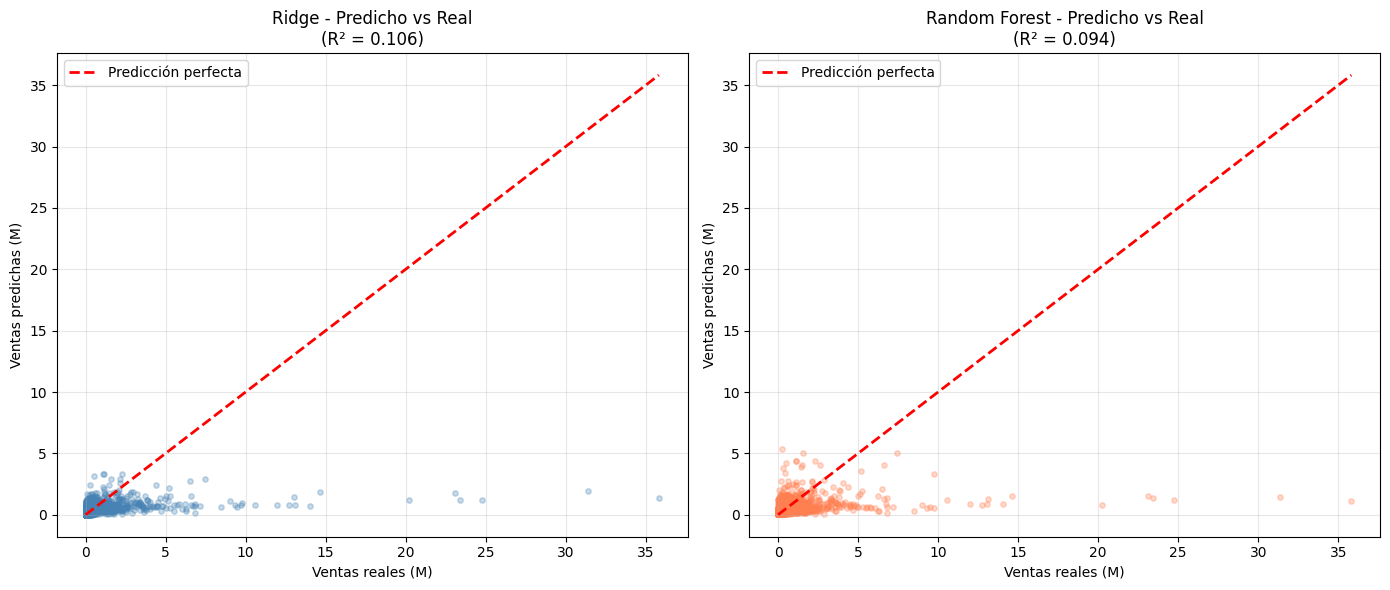

Observación: los puntos deberían agruparse sobre la diagonal roja.
Se espera ver mayor dispersión en la zona de valores altos (blockbusters),
indicando que el modelo tiene dificultad para predecir con precisión los éxitos extremos.


In [19]:
# ============================================================
# GRÁFICO 1: PREDICHO vs REAL
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Ridge
axes[0].scatter(y_test, y_pred_ridge, alpha=0.3, color='steelblue', s=15)
axes[0].plot([0, y_test.max()], [0, y_test.max()], 'r--', linewidth=2, label='Predicción perfecta')
axes[0].set_xlabel('Ventas reales (M)')
axes[0].set_ylabel('Ventas predichas (M)')
axes[0].set_title(f'Ridge - Predicho vs Real\n(R² = {r2_ridge:.3f})')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Random Forest
axes[1].scatter(y_test, y_pred_rf, alpha=0.3, color='coral', s=15)
axes[1].plot([0, y_test.max()], [0, y_test.max()], 'r--', linewidth=2, label='Predicción perfecta')
axes[1].set_xlabel('Ventas reales (M)')
axes[1].set_ylabel('Ventas predichas (M)')
axes[1].set_title(f'Random Forest - Predicho vs Real\n(R² = {r2_rf:.3f})')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Observación: los puntos deberían agruparse sobre la diagonal roja.")
print("Se espera ver mayor dispersión en la zona de valores altos (blockbusters),")
print("indicando que el modelo tiene dificultad para predecir con precisión los éxitos extremos.")

### 3.6.2. Análisis de residuos

Los **residuos** son la diferencia entre los valores reales y los predichos (`residuo = real - predicho`). Su distribución permite detectar sesgos sistemáticos del modelo:

- Si los residuos están **centrados en cero** y son **simétricos**, el modelo no tiene sesgo.
- Si hay una cola larga hacia valores positivos, el modelo tiende a **subestimar** las ventas.
- Si hay una cola larga hacia valores negativos, tiende a **sobreestimar**.

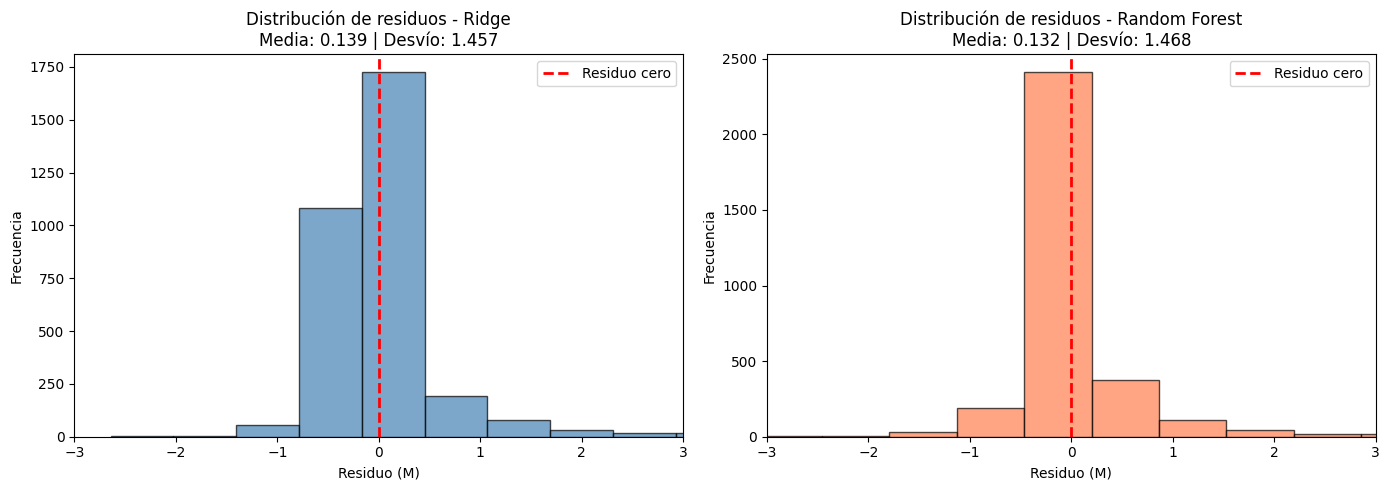

Análisis cuantitativo de residuos:

Ridge:
  Media: 0.1392 (idealmente 0)
  Desvío: 1.4569
  % residuos positivos (subestima): 38.4%
  % residuos negativos (sobreestima): 61.6%

Random Forest:
  Media: 0.1316 (idealmente 0)
  Desvío: 1.4677
  % residuos positivos (subestima): 35.1%
  % residuos negativos (sobreestima): 64.9%


In [20]:
# ============================================================
# GRÁFICO 2: DISTRIBUCIÓN DE RESIDUOS
# ============================================================

residuos_ridge = y_test.values - y_pred_ridge
residuos_rf = y_test.values - y_pred_rf

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de residuos - Ridge
axes[0].hist(residuos_ridge, bins=60, color='steelblue', alpha=0.7, edgecolor='black')
axes[0].axvline(x=0, color='red', linestyle='--', linewidth=2, label='Residuo cero')
axes[0].set_xlim(-3, 3)
axes[0].set_xlabel('Residuo (M)')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title(f'Distribución de residuos - Ridge\nMedia: {residuos_ridge.mean():.3f} | Desvío: {residuos_ridge.std():.3f}')
axes[0].legend()

# Histograma de residuos - Random Forest
axes[1].hist(residuos_rf, bins=60, color='coral', alpha=0.7, edgecolor='black')
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2, label='Residuo cero')
axes[1].set_xlim(-3, 3)
axes[1].set_xlabel('Residuo (M)')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title(f'Distribución de residuos - Random Forest\nMedia: {residuos_rf.mean():.3f} | Desvío: {residuos_rf.std():.3f}')
axes[1].legend()

plt.tight_layout()
plt.show()

# Interpretación cuantitativa
print("Análisis cuantitativo de residuos:")
print(f"\nRidge:")
print(f"  Media: {residuos_ridge.mean():.4f} (idealmente 0)")
print(f"  Desvío: {residuos_ridge.std():.4f}")
print(f"  % residuos positivos (subestima): {(residuos_ridge > 0).mean()*100:.1f}%")
print(f"  % residuos negativos (sobreestima): {(residuos_ridge < 0).mean()*100:.1f}%")

print(f"\nRandom Forest:")
print(f"  Media: {residuos_rf.mean():.4f} (idealmente 0)")
print(f"  Desvío: {residuos_rf.std():.4f}")
print(f"  % residuos positivos (subestima): {(residuos_rf > 0).mean()*100:.1f}%")
print(f"  % residuos negativos (sobreestima): {(residuos_rf < 0).mean()*100:.1f}%")

### 3.6.3. Importancia de features (Random Forest)

El Random Forest permite extraer la **importancia relativa** de cada variable. Este score refleja cuánto contribuye cada feature a reducir el error del modelo. Es una ventaja del RF sobre Ridge, ya que este último solo entrega coeficientes que pueden estar afectados por la escala de las variables.

Analizar las top variables nos permite entender **qué información está usando el modelo** para predecir las ventas.|

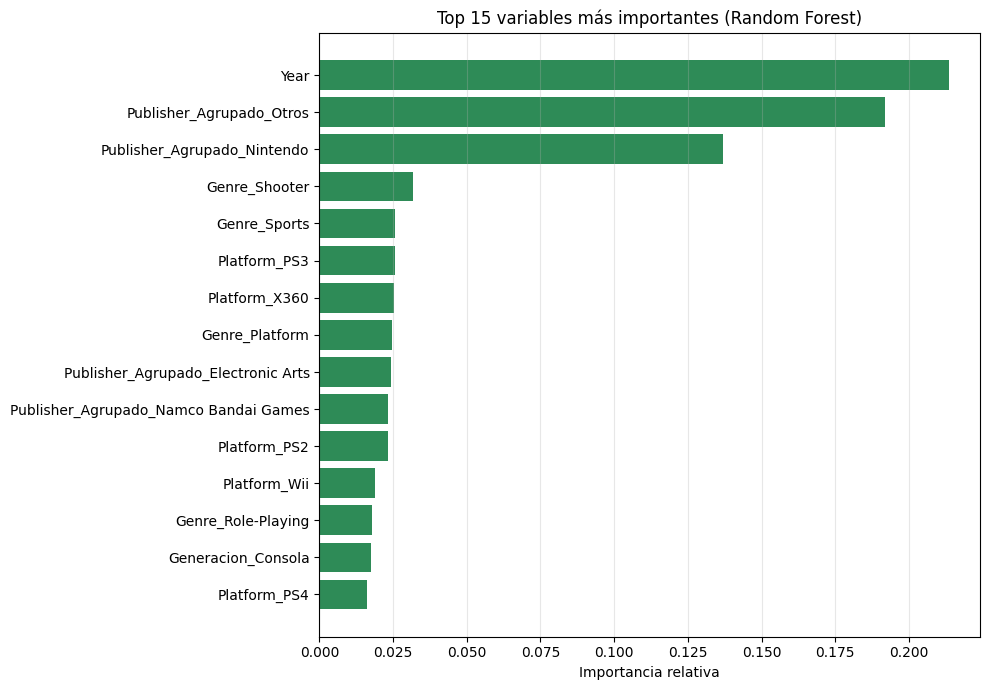

Top 10 variables más importantes:
                              Feature  Importancia
                                 Year     0.213391
             Publisher_Agrupado_Otros     0.191923
          Publisher_Agrupado_Nintendo     0.136833
                        Genre_Shooter     0.031752
                         Genre_Sports     0.025679
                         Platform_PS3     0.025532
                        Platform_X360     0.025207
                       Genre_Platform     0.024493
   Publisher_Agrupado_Electronic Arts     0.024165
Publisher_Agrupado_Namco Bandai Games     0.023416

Concentración de importancia:
  Top 5 variables acumulan: 60.0% de la importancia
  Top 10 variables acumulan: 72.2% de la importancia


In [21]:
# ============================================================
# GRÁFICO 3: IMPORTANCIA DE FEATURES (Random Forest)
# ============================================================

importancias = pd.DataFrame({
    'Feature': X_train.columns,
    'Importancia': modelo_rf.feature_importances_
}).sort_values('Importancia', ascending=False)

# Top 15 features más importantes
top_15 = importancias.head(15)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_15['Feature'][::-1], top_15['Importancia'][::-1], color='seagreen')
ax.set_xlabel('Importancia relativa')
ax.set_title('Top 15 variables más importantes (Random Forest)')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print("Top 10 variables más importantes:")
print(top_15.head(10).to_string(index=False))

# Concentración: ¿cuánta importancia acumulan las top variables?
top_5_imp = importancias.head(5)['Importancia'].sum()
top_10_imp = importancias.head(10)['Importancia'].sum()
print(f"\nConcentración de importancia:")
print(f"  Top 5 variables acumulan: {top_5_imp*100:.1f}% de la importancia")
print(f"  Top 10 variables acumulan: {top_10_imp*100:.1f}% de la importancia")

### 3.6.4. Análisis de los peores errores

Se identifican los 10 casos donde el modelo Random Forest cometió los errores absolutos más grandes. Este análisis es útil para entender **en qué tipo de juegos falla el modelo** y evaluar si hay algún patrón sistemático (por ejemplo, si todos los peores errores son blockbusters, o si vienen de plataformas específicas).

In [22]:
# ============================================================
# ANÁLISIS DE LOS PEORES ERRORES (Random Forest)
# ============================================================

# Reconstruimos el índice original para recuperar Name y Platform de los peores errores
# El X_test conserva los índices originales del df_fe
indices_test = X_test.index

# Creamos un dataframe con la info relevante
analisis_errores = pd.DataFrame({
    'Nombre': df_fe.loc[indices_test, 'Name'].values,
    'Plataforma': df_fe.loc[indices_test, 'Platform'].values,
    'Genero': df_fe.loc[indices_test, 'Genre'].values,
    'Publisher': df_fe.loc[indices_test, 'Publisher'].values,
    'Ventas_Reales': y_test.values,
    'Predicho_RF': y_pred_rf.round(3),
    'Error_Absoluto': np.abs(y_test.values - y_pred_rf).round(3)
})

# Top 10 peores errores
peores_errores = analisis_errores.sort_values('Error_Absoluto', ascending=False).head(10)

print("="*90)
print("TOP 10 PEORES PREDICCIONES DEL RANDOM FOREST")
print("="*90)
print(peores_errores.to_string(index=False))

# Observaciones automáticas
print(f"\nObservaciones:")
print(f"  Error promedio en los 10 peores casos: {peores_errores['Error_Absoluto'].mean():.2f}M")
print(f"  Error promedio general (MAE): {mae_rf:.2f}M")
print(f"  Ratio: los peores errores son {peores_errores['Error_Absoluto'].mean()/mae_rf:.1f}x el error promedio.")

# ¿Los peores errores son sobreestimaciones o subestimaciones?
subestimados = (peores_errores['Ventas_Reales'] > peores_errores['Predicho_RF']).sum()
print(f"\n  De los 10 peores: {subestimados} son subestimaciones y {10-subestimados} son sobreestimaciones.")

TOP 10 PEORES PREDICCIONES DEL RANDOM FOREST
                                      Nombre Plataforma       Genero  Publisher  Ventas_Reales  Predicho_RF  Error_Absoluto
                              Mario Kart Wii        Wii       Racing   Nintendo          35.82        1.100          34.720
                    Pokemon Red/Pokemon Blue         GB Role-Playing   Nintendo          31.37        1.428          29.942
                                  Nintendogs         DS   Simulation   Nintendo          24.76        1.175          23.585
                               Mario Kart DS         DS       Racing   Nintendo          23.42        1.400          22.020
                 Pokemon Gold/Pokemon Silver         GB Role-Playing   Nintendo          23.10        1.527          21.573
Brain Age: Train Your Brain in Minutes a Day         DS         Misc   Nintendo          20.22        0.786          19.434
                  Call of Duty: Black Ops II        PS3      Shooter Activision        

## 3.7. Conclusiones

### Resumen del proyecto

Se desarrolló un modelo de regresión para predecir las ventas globales (`Global_Sales`) de un videojuego a partir de sus características iniciales: plataforma, año de lanzamiento, género, publisher y variables derivadas creadas mediante feature engineering (`Decada`, `Generacion_Consola`, `Publisher_Agrupado`).

Se compararon dos modelos con perfiles complementarios: **Regresión Ridge** como baseline lineal interpretable y **Random Forest Regressor** como modelo no lineal capaz de capturar interacciones entre variables.

### Rendimiento obtenido

Sobre el conjunto de test, ambos modelos alcanzaron resultados similares:

| Métrica | Ridge | Random Forest |
|---|---|---|
| MAE (M) | 0.4436 | 0.4413 |
| RMSE (M) | 1.4636 | 1.4735 |
| R² | 0.1060 | 0.0937 |

La validación cruzada (K-Fold con k=5) muestra un rendimiento **estable entre folds** (desvío del R² ≤ 0.026), por lo que los resultados no dependen de una partición particular. El R² de validación (0.26–0.28) se calculó en escala logarítmica, por eso es mayor que el de test (0.09–0.11), medido en millones.

### Qué predice bien el modelo

El modelo capta la tendencia general (qué combinaciones de año, publisher, plataforma y género venden más), pero con poca precisión individual: el error típico (MAE ≈ 0.44M) es más del doble de la mediana de ventas (0.17M). Tiende a **sobreestimar** los juegos de ventas bajas (62–65% de los residuos son negativos) y a **subestimar fuertemente** los grandes éxitos.

### Dónde falla el modelo

El análisis de residuos y de los peores errores muestra un **sesgo sistemático de subestimación** en los juegos de ventas extremas (blockbusters como Mario Kart Wii, Pokémon Red/Blue, Nintendogs o Call of Duty: Black Ops II). El modelo tiende a predecir valores conservadores en la cola derecha de la distribución.

Esto es **esperable y en cierto modo inevitable** con las variables disponibles: características como "plataforma Wii" o "género Sports" son necesarias pero no suficientes para explicar por qué un juego específico se convierte en fenómeno cultural. Factores como marketing, calidad narrativa, contexto sociocultural o timing de lanzamiento son intrínsecamente difíciles de codificar como variables tabulares.

### Comparación entre modelos

Un hallazgo interesante es que **Ridge y Random Forest rinden de forma muy similar** (diferencia menor al 1% en MAE). Esto sugiere que:

1. La señal predictiva está **más limitada por las features disponibles** que por la complejidad del modelo.
2. Agregar modelos más sofisticados (XGBoost, redes neuronales) probablemente no aportaría ganancia significativa sin incorporar nuevas variables.
3. Para uso práctico, Ridge sería preferible por su **mayor interpretabilidad** y menor costo computacional, salvo que se priorice la captura de casos extremos.

### Limitaciones del proyecto

- **Cobertura temporal**: el dataset llega principalmente hasta 2016, por lo que el modelo no capta plataformas y géneros posteriores (por ejemplo, PS5, Xbox Series, o el auge de los free-to-play).
- **Falta de features cualitativas**: no se dispone de información sobre calidad (rating de críticos, puntuaciones de usuarios), presupuesto de marketing ni desarrollador.
- **Outliers extremos**: hay pocos casos por encima de 20M de ventas, lo que dificulta que cualquier modelo aprenda su patrón.
- **Distribución sesgada del target**: aunque se aplicó `log1p` para mitigar el problema, la cola larga sigue afectando las predicciones en los valores altos.

### Posibilidades de mejora

- **Hyperparameter tuning**: usar `GridSearchCV` o `RandomizedSearchCV` para explorar combinaciones de `alpha` (Ridge) y `n_estimators`/`max_depth`/`min_samples_leaf` (RF).
- **Feature engineering adicional**: crear variables de interacción (por ejemplo, `Plataforma × Publisher`), o usar embeddings de publisher/plataforma en lugar de one-hot.
- **Datos externos**: incorporar datasets complementarios con puntuaciones de crítica (Metacritic, IGN) o presencia en redes sociales.
- **Modelos alternativos**: probar **XGBoost** o **LightGBM**, que suelen mejorar sobre Random Forest en tabular. También podría considerarse un **modelo en dos etapas**: uno que clasifique si un juego será blockbuster (>5M) y otro que estime las ventas dentro de cada segmento.
- **Ampliar el dataset**: incluir juegos posteriores a 2016 y plataformas modernas.

### Utilidad práctica

Aunque el modelo no puede predecir con precisión los éxitos extremos, sí resulta útil como **estimador base para nuevos lanzamientos**: permite a un editor o publisher tener una expectativa de ventas conservadora a partir de las decisiones iniciales del producto (plataforma, género, año). También sirve como **detector de casos atípicos**: si el modelo predice 0.5M y un juego termina vendiendo 15M, ese gap identifica un fenómeno inesperado que merece análisis cualitativo.

En un contexto real, este tipo de modelo puede integrarse como **una señal más** en una decisión de negocio (junto con estudios de mercado, focus groups, análisis competitivo), no como una predicción autónoma.

---

## 4. Anexo final

### 4.1. Dataset utilizado

- **Nombre**: Video Game Sales
- **Fuente**: Kaggle (dataset público)
- **Link**: [https://www.kaggle.com/datasets/gregorut/videogamesales](https://www.kaggle.com/datasets/gregorut/videogamesales)
- **Autor original**: Gregory Smith
- **Cantidad de registros**: 16.598 juegos
- **Cantidad de variables originales**: 11 columnas
- **Descripción**: dataset construido a partir del sitio VGChartz.com, con información sobre ventas de videojuegos con más de 100.000 copias vendidas globalmente. Cubre lanzamientos desde 1980 hasta 2020, con la mayoría concentrada entre 1995 y 2016.

### 4.2. Herramientas y librerías utilizadas

| Librería | Uso principal |
|---|---|
| `pandas` | Manipulación de datos tabulares |
| `numpy` | Operaciones numéricas y transformaciones (log1p / expm1) |
| `matplotlib` | Visualizaciones estáticas |
| `seaborn` | Visualizaciones estadísticas (heatmap, histogramas) |
| `scikit-learn` | Modelos, preprocesamiento, métricas y validación cruzada |

### 4.3. Documentación consultada

- Documentación oficial de **scikit-learn**: [https://scikit-learn.org/stable/](https://scikit-learn.org/stable/)
    - `Ridge` y regularización L2.
    - `RandomForestRegressor` y sus hiperparámetros.
    - `train_test_split` con estratificación.
    - `cross_val_score` y `KFold`.
- Documentación de **pandas** para `pd.cut`, `pd.get_dummies` y agregaciones con `groupby`.
- Guía sobre **feature engineering para variables categóricas de alta cardinalidad** (One-Hot Encoding vs agrupamiento de categorías infrecuentes).

### 4.4. Decisiones metodológicas relevantes

Se resumen las decisiones técnicas clave tomadas a lo largo del proyecto:

1. **Eliminación de las ventas regionales** (`NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales`) para evitar fuga de datos, ya que la variable objetivo `Global_Sales` es la suma de esos valores.

2. **Conservación de outliers** en `Global_Sales`: los valores extremos (Wii Sports 82.74M, Super Mario Bros. 40.24M) corresponden a lanzamientos reales y no a errores de carga, por lo que se preservaron para que el modelo pueda aprender que existen ventas excepcionales.

3. **Split estratificado por cuantiles del target**: dada la distribución muy sesgada de `Global_Sales`, se estratificó el split para que train y test conserven la misma proporción de valores bajos, medios, altos y extremos.

4. **Transformación logarítmica del target** (`log1p`): se aplicó para comprimir la cola larga y facilitar el aprendizaje de los modelos. Las predicciones se devolvieron a la escala original con `expm1` para el reporte de métricas.

5. **Agrupamiento de publishers**: dado que existen 576 publishers únicos y los top 20 concentran el 85.7% de las ventas, se agruparon los publishers menos frecuentes en una categoría "Otros" para controlar la cardinalidad.

6. **Feature engineering temporal**: creación de las variables `Decada` y `Generacion_Consola` para capturar efectos del ciclo del mercado y de las plataformas más allá del `Year` puntual.

### 4.5. Aclaraciones adicionales

- El proyecto se desarrolló en **Google Colab** con Python 3.
- El `random_state=42` se usó de forma consistente en todas las divisiones y modelos aleatorios para garantizar la **reproducibilidad** de los resultados.
- Las métricas de la validación cruzada están reportadas en **escala logarítmica** (log1p), ya que el modelo fue entrenado con el target transformado. Las métricas del conjunto de test están reportadas en **escala original** (millones de unidades) para facilitar la interpretación.
- El código está estructurado de forma **secuencial**: cada celda depende de las anteriores. Para reproducir los resultados, se debe ejecutar el notebook completo desde el inicio.

---

*Fin del proyecto integrador — Machine Learning.*